# 🕳️ Pothole Detector — **YOLO nano** edition (built for real-time video)

**Pipeline:** download Kaggle pothole data → validate & split → convert to YOLO format (+ extra augmented copies for robustness) → fine-tune a **COCO-pretrained YOLO11n** → evaluate on a held-out test set → **calibrate the confidence threshold** → export → **real-time video script** + test on your own images/videos.

### How to run
1. **Runtime → Change runtime type → T4 GPU**
2. First time? In the config cell set `SMOKE_TEST = True` (≈3 min pipeline check), then set it back to `False`.
3. **Runtime → Run all.** The last two cells (your own images / your own video) ask you to upload files, so they are placed at the very end.

### What changed vs. the Faster R-CNN notebook
| | Faster R-CNN notebook | This notebook (YOLO11n) |
|---|---|---|
| Speed on a laptop CPU | ~1–3 FPS | ~10–30 FPS (GPU: 100+) |
| Model size | ~19M params / 75 MB | ~2.6M params / ~5 MB |
| Augmentation | own NumPy aug (online) | **own aug as offline extra copies** (shadows, blur, JPEG, low-res…) **+** YOLO's built-in mosaic / mixup / HSV / scale / flip online |
| Evaluation | own AP / F1 | own AP / F1 **and** Ultralytics' official mAP |
| Threshold | calibrated on val (max F1) | same — saved to `config.json` |

> **Preprocessing:** with YOLO you simply hand over the **frame** (a BGR array from OpenCV, or a file path). Resizing, letter-boxing and 0–1 scaling happen inside the library. Boxes come back in original-frame pixel coordinates.

## 1 · Setup & configuration

In [ ]:
import os, sys, json, glob, math, time, random, copy, shutil, subprocess, warnings, urllib.request, importlib
import xml.etree.ElementTree as ET
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch

# ═════════════════════════  CONFIG — edit here  ═════════════════════════
SMOKE_TEST = False          # True = tiny 2-epoch run on 48 images just to check the pipeline works

CFG = dict(
    MODEL         = "yolo11n.pt",  # "yolo11n.pt" (default) | "yolov8n.pt" | "yolo11s.pt" (bigger/more accurate, ~2x slower)
    IMGSZ         = 640,           # training/inference image size (416 = faster live video, 640 = more accurate)
    EPOCHS        = 100,
    PATIENCE      = 25,            # early-stop if val mAP does not improve for this many epochs
    BATCH         = 16,
    N_OFFLINE_AUG = 2,             # extra augmented copies of every TRAIN image (shadows, blur, JPEG, low-res, zoom…)
    SEED          = 42,
    VAL_FRAC      = 0.15,
    TEST_FRAC     = 0.15,
    NUM_WORKERS   = 2,
    USE_DRIVE     = True,          # keep results on Google Drive so a disconnect never loses progress
    RESUME        = True,          # continue an unfinished run if one exists (False = always start fresh)
    DATA_DIR      = None,          # set to a folder to skip downloading (images + Pascal-VOC .xml files)
    EXPORT        = ["onnx"],      # extra export formats, e.g. ["onnx", "openvino"] (openvino = big CPU speed-up on Intel)
)
DATASET_SLUG = "andrewmvd/pothole-detection"
# ═══════════════════════════════════════════════════════════════════════

if SMOKE_TEST:
    CFG.update(EPOCHS=2, PATIENCE=2, IMGSZ=320, N_OFFLINE_AUG=0, RESUME=False, EXPORT=[])

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG["SEED"])

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

try:
    import ultralytics
except ImportError:
    print("Installing ultralytics …"); _pip("ultralytics"); importlib.invalidate_caches(); import ultralytics
from ultralytics import YOLO

DEVICE = 0 if torch.cuda.is_available() else "cpu"
IMGSZ, EPOCHS = CFG["IMGSZ"], CFG["EPOCHS"]
print(f"ultralytics {ultralytics.__version__} | torch {torch.__version__} | opencv {cv2.__version__}")
if DEVICE == "cpu":
    print("⚠️  NO GPU DETECTED. Training on CPU is very slow.\n    Runtime → Change runtime type → T4 GPU, then Runtime → Run all.")
else:
    print("GPU:", torch.cuda.get_device_name(0))
print(f"model={CFG['MODEL']} | imgsz={IMGSZ} | epochs={EPOCHS} | smoke={SMOKE_TEST}")

ultralytics 8.4.209 | torch 2.14.1+cu130 | opencv 4.14.0
GPU: Tesla T4
model=yolo11n.pt | imgsz=640 | epochs=100 | smoke=False


## 2 · Output folder (Google Drive, with local fallback)

In [ ]:
IN_COLAB = "google.colab" in sys.modules
OUT_DIR = "/content/pothole_detector" if IN_COLAB else os.path.abspath("./pothole_detector")

if CFG["USE_DRIVE"] and IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = "/content/drive/MyDrive/pothole_detector"
    except Exception as e:
        print("Drive mount failed -> saving locally instead (lost if the runtime resets). Reason:", repr(e)[:150])

os.makedirs(OUT_DIR, exist_ok=True)
PREFIX = "smoke_" if SMOKE_TEST else ""
CKPT_LAST = os.path.join(OUT_DIR, PREFIX + "last.pt")
CKPT_BEST = os.path.join(OUT_DIR, PREFIX + "best.pt")
print("Checkpoints & results go to:", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoints & results go to: /content/drive/MyDrive/pothole_detector


## 3 · Get the dataset
Tries, in order: Kaggle download without login → Colab secrets (`KAGGLE_USERNAME`, `KAGGLE_KEY`) → upload your `kaggle.json` → upload the dataset zip manually.

In [ ]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

def scan_voc(root):
    """Find every image + Pascal-VOC xml under root (any folder layout) and pair them by file stem."""
    imgs, xmls = {}, {}
    for dp, _, fns in os.walk(root):
        for fn in sorted(fns):
            stem, ext = os.path.splitext(fn); ext = ext.lower(); full = os.path.join(dp, fn)
            if ext in IMG_EXT: imgs.setdefault(stem, full)
            elif ext == ".xml": xmls.setdefault(stem, full)
    pairs = [(imgs[s], xmls[s]) for s in sorted(imgs) if s in xmls]
    return pairs, len(imgs), len(xmls)

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

def _kagglehub_download():
    try:
        import kagglehub
    except ImportError:
        _pip("kagglehub"); importlib.invalidate_caches(); import kagglehub
    return kagglehub.dataset_download(DATASET_SLUG)

def locate_dataset():
    if CFG["DATA_DIR"]:
        return CFG["DATA_DIR"]
    try:                                                    # A) plain kagglehub (public dataset)
        return _kagglehub_download()
    except Exception as e:
        print("• kagglehub without login failed:", repr(e)[:160])
    try:                                                    # B) Colab secrets
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        return _kagglehub_download()
    except Exception as e:
        print("• Colab-secrets route failed:", repr(e)[:160])
    try:                                                    # C) upload kaggle.json
        from google.colab import files
        print("\nUpload your kaggle.json (kaggle.com → Settings → API → Create New Token). Cancel to skip.")
        up = files.upload()
        if up:
            creds = json.loads(next(iter(up.values())).decode())
            os.environ["KAGGLE_USERNAME"] = creds["username"]; os.environ["KAGGLE_KEY"] = creds["key"]
            return _kagglehub_download()
    except Exception as e:
        print("• kaggle.json route failed:", repr(e)[:160])
    try:                                                    # D) manual zip upload
        from google.colab import files
        import zipfile
        print("\nDownload the dataset zip from https://www.kaggle.com/datasets/andrewmvd/pothole-detection and upload it here.")
        up = files.upload()
        if up:
            dest = "/content/pothole_data"; os.makedirs(dest, exist_ok=True)
            with zipfile.ZipFile(next(iter(up))) as z: z.extractall(dest)
            return dest
    except Exception as e:
        print("• zip route failed:", repr(e)[:160])
    raise RuntimeError("Could not obtain the dataset. Set CFG['DATA_DIR'] to a folder that contains the images and XML files.")

DATA_ROOT = locate_dataset()
pairs, n_img, n_xml = scan_voc(DATA_ROOT)
print(f"\nDataset root: {DATA_ROOT}\nimages found: {n_img} | xml found: {n_xml} | matched image+xml pairs: {len(pairs)}")
assert len(pairs) >= 50, ("Too few image/annotation pairs found. Folder contents: " + str(os.listdir(DATA_ROOT)[:20]))

Using Colab cache for faster access to the 'pothole-detection' dataset.

Dataset root: /kaggle/input/pothole-detection
images found: 665 | xml found: 665 | matched image+xml pairs: 665


## 4 · Parse & validate annotations, split the data
Every image is opened and every XML parsed once. Corrupt files are skipped, boxes are clipped to the image, degenerate boxes are dropped, and boxes are rescaled if the XML's declared size differs from the real image.

usable samples: 665 | skipped: 0 | boxes rescaled to real image size: 0
object names found in XML: {'pothole'} (all treated as the single class 'pothole')
split → train 467 | val 99 | test 99


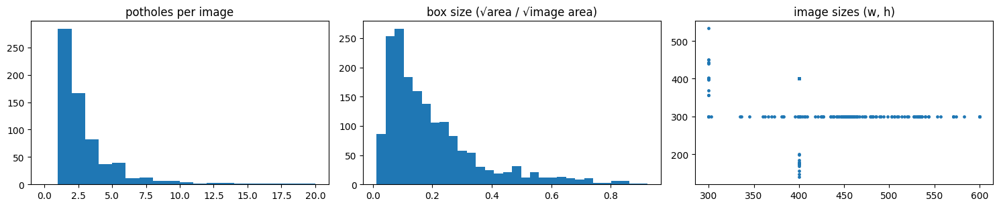

total boxes: 1739 | images without boxes: 0


In [ ]:
def read_bgr(path, ignore_orientation=True):
    """Unicode-safe image read. Training data ignores EXIF rotation so it stays aligned with the XML boxes."""
    data = np.fromfile(path, dtype=np.uint8)
    if data.size == 0: return None
    flags = cv2.IMREAD_COLOR | (cv2.IMREAD_IGNORE_ORIENTATION if ignore_orientation else 0)
    return cv2.imdecode(data, flags)

def parse_voc(xml_path):
    root = ET.parse(xml_path).getroot()
    boxes, names = [], []
    for obj in root.findall("object"):
        bb = obj.find("bndbox")
        if bb is None: continue
        boxes.append([float(bb.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax")])
        names.append((obj.findtext("name") or "").strip())
    size = None
    sz = root.find("size")
    if sz is not None:
        try: size = (float(sz.findtext("width")), float(sz.findtext("height")))
        except Exception: size = None
    return np.array(boxes, dtype=np.float32).reshape(-1, 4), size, names

def clean_boxes(b, w, h, min_size=2.0):
    if len(b) == 0: return b.reshape(0, 4).astype(np.float32)
    b = b.copy().astype(np.float32)
    b[:, [0, 2]] = b[:, [0, 2]].clip(0, w); b[:, [1, 3]] = b[:, [1, 3]].clip(0, h)
    keep = ((b[:, 2] - b[:, 0]) >= min_size) & ((b[:, 3] - b[:, 1]) >= min_size)
    return b[keep]

records, skipped, class_names, n_rescaled = [], [], set(), 0
for ip, xp in pairs:
    try:
        img = read_bgr(ip)
        if img is None: raise ValueError("unreadable image")
        h, w = img.shape[:2]
        boxes, xsize, names = parse_voc(xp); class_names.update(names)
        if xsize and xsize[0] > 0 and xsize[1] > 0 and (abs(xsize[0] - w) > 1 or abs(xsize[1] - h) > 1):
            sx, sy = w / xsize[0], h / xsize[1]
            boxes = boxes * np.array([sx, sy, sx, sy], dtype=np.float32); n_rescaled += 1
        records.append(dict(img=ip, xml=xp, boxes=clean_boxes(boxes, w, h), w=w, h=h))
    except Exception as e:
        skipped.append((os.path.basename(ip), repr(e)[:80]))

print(f"usable samples: {len(records)} | skipped: {len(skipped)} | boxes rescaled to real image size: {n_rescaled}")
print("object names found in XML:", class_names, "(all treated as the single class 'pothole')")
for s in skipped[:5]: print("  skipped:", s)
assert len(records) >= 50, "Not enough valid samples."

# ---- reproducible split (by image) ----
ids = list(range(len(records))); random.Random(CFG["SEED"]).shuffle(ids)
if SMOKE_TEST: ids = ids[:48]
n_test = max(1, int(len(ids) * CFG["TEST_FRAC"])); n_val = max(1, int(len(ids) * CFG["VAL_FRAC"]))
test_ids, val_ids, train_ids = ids[:n_test], ids[n_test:n_test + n_val], ids[n_test + n_val:]
train_recs = [records[i] for i in train_ids]; val_recs = [records[i] for i in val_ids]; test_recs = [records[i] for i in test_ids]
print(f"split → train {len(train_recs)} | val {len(val_recs)} | test {len(test_recs)}")

# ---- quick look at the data ----
nb = np.array([len(r["boxes"]) for r in records])
rel = np.concatenate([np.sqrt(((r["boxes"][:, 2] - r["boxes"][:, 0]) * (r["boxes"][:, 3] - r["boxes"][:, 1])) / (r["w"] * r["h"])) for r in records if len(r["boxes"])] or [np.zeros(1)])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
ax[0].hist(nb, bins=range(0, nb.max() + 2)); ax[0].set_title("potholes per image")
ax[1].hist(rel, bins=30); ax[1].set_title("box size (√area / √image area)")
ax[2].scatter([r["w"] for r in records], [r["h"] for r in records], s=6); ax[2].set_title("image sizes (w, h)")
plt.tight_layout(); plt.show()
print(f"total boxes: {nb.sum()} | images without boxes: {(nb == 0).sum()}")

## 5 · Box-aware augmentation (pure NumPy/OpenCV)
Used here to create **extra augmented copies of the training images** (offline). YOLO then applies its own online augmentation on top (mosaic, mixup, HSV, scale, translate, flip). Geometric transforms move the boxes with the pixels; crops never leave half-visible, unlabeled potholes behind.

In [ ]:
MAX_SIDE_LOAD = 1280   # very large source images are shrunk on load (saves RAM/time)

def load_sample(rec):
    img = cv2.cvtColor(read_bgr(rec["img"]), cv2.COLOR_BGR2RGB)
    boxes = rec["boxes"].copy()
    h, w = img.shape[:2]
    s = MAX_SIDE_LOAD / max(h, w)
    if s < 1:
        nw, nh = int(round(w * s)), int(round(h * s))
        img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA); boxes = boxes * s; h, w = nh, nw
    return np.ascontiguousarray(img), clean_boxes(boxes, w, h)

# ---------------- geometric ----------------
def aug_hflip(img, boxes):
    w = img.shape[1]
    img = np.ascontiguousarray(img[:, ::-1])
    if len(boxes): boxes = boxes.copy(); boxes[:, [0, 2]] = w - boxes[:, [2, 0]]
    return img, boxes

def aug_stretch(img, boxes, rng, lo=0.8, hi=1.25):
    """Independent x/y scaling → simulates different aspect ratios / camera optics."""
    h, w = img.shape[:2]
    sx, sy = rng.uniform(lo, hi), rng.uniform(lo, hi)
    nw, nh = max(32, int(round(w * sx))), max(32, int(round(h * sy)))
    img = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    if len(boxes): boxes = boxes * np.array([nw / w, nh / h, nw / w, nh / h], dtype=np.float32)
    return img, boxes

def aug_zoom_out(img, boxes, rng, max_ratio=2.5):
    """Paste the image on a larger canvas → potholes become smaller / farther away."""
    h, w = img.shape[:2]
    r = rng.uniform(1.2, max_ratio)
    H, W = int(h * r), int(w * r)
    canvas = np.empty((H, W, 3), dtype=np.uint8); canvas[:] = img.reshape(-1, 3).mean(0).astype(np.uint8)
    x0 = int(rng.integers(0, W - w + 1)); y0 = int(rng.integers(0, H - h + 1))
    canvas[y0:y0 + h, x0:x0 + w] = img
    if len(boxes): boxes = boxes + np.array([x0, y0, x0, y0], dtype=np.float32)
    return canvas, boxes

def aug_crop(img, boxes, rng, tries=25):
    """Random zoom-in crop. Keeps boxes that are >=50% visible; rejects crops that would leave
    a partly visible, now-unlabeled pothole (would teach the model that potholes are background)."""
    if len(boxes) == 0: return img, boxes
    h, w = img.shape[:2]
    area0 = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    for _ in range(tries):
        s, ar = rng.uniform(0.45, 1.0), rng.uniform(0.75, 1.33)
        cw, ch = int(w * math.sqrt(s * ar)), int(h * math.sqrt(s / ar))
        if cw > w or ch > h or cw < 48 or ch < 48: continue
        x0 = int(rng.integers(0, w - cw + 1)); y0 = int(rng.integers(0, h - ch + 1))
        nb = boxes - np.array([x0, y0, x0, y0], dtype=np.float32)
        nb[:, [0, 2]] = nb[:, [0, 2]].clip(0, cw); nb[:, [1, 3]] = nb[:, [1, 3]].clip(0, ch)
        bw, bh = nb[:, 2] - nb[:, 0], nb[:, 3] - nb[:, 1]
        frac = (bw * bh) / np.maximum(area0, 1e-6)
        keep = (frac >= 0.5) & (bw >= 2) & (bh >= 2)
        if keep.sum() == 0: continue
        if ((frac > 0.1) & ~keep).any(): continue          # ambiguous partial box → try another crop
        return np.ascontiguousarray(img[y0:y0 + ch, x0:x0 + cw]), nb[keep]
    return img, boxes

# ---------------- photometric / degradation ----------------
def aug_shadow(img, rng):
    h, w = img.shape[:2]
    pts = np.stack([rng.uniform(0, w, 4), rng.uniform(0, h, 4)], 1).astype(np.int32)
    mask = np.zeros((h, w), np.float32); cv2.fillPoly(mask, [pts], 1.0)
    k = max(3, (min(h, w) // 6) | 1)
    mask = cv2.GaussianBlur(mask, (k, k), 0)
    f = rng.uniform(0.45, 0.8)
    return np.clip(img.astype(np.float32) * (1 - mask[..., None] * (1 - f)), 0, 255).astype(np.uint8)

def aug_motion_blur(img, rng):
    k = int(rng.choice([5, 7, 9, 11]))
    kern = np.zeros((k, k), np.float32); kern[k // 2, :] = 1
    M = cv2.getRotationMatrix2D(((k - 1) / 2, (k - 1) / 2), float(rng.uniform(0, 180)), 1.0)
    kern = cv2.warpAffine(kern, M, (k, k)); kern /= max(kern.sum(), 1e-6)
    return cv2.filter2D(img, -1, kern)

def aug_jpeg(img, rng):
    q = int(rng.integers(25, 85))
    ok, enc = cv2.imencode(".jpg", cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [int(cv2.IMWRITE_JPEG_QUALITY), q])
    return cv2.cvtColor(cv2.imdecode(enc, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB) if ok else img

def aug_lowres(img, rng):
    h, w = img.shape[:2]; s = rng.uniform(0.35, 0.8)
    small = cv2.resize(img, (max(16, int(w * s)), max(16, int(h * s))), interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)

def aug_photometric(img, rng):
    out = img.astype(np.float32)
    if rng.random() < 0.8:                                   # contrast + brightness
        out = out * rng.uniform(0.6, 1.4) + rng.uniform(-40, 40)
    if rng.random() < 0.3:                                   # gamma
        out = 255.0 * (np.clip(out, 0, 255) / 255.0) ** rng.uniform(0.6, 1.6)
    out = np.clip(out, 0, 255).astype(np.uint8)
    if rng.random() < 0.5:                                   # hue / saturation / value
        hsv = cv2.cvtColor(out, cv2.COLOR_RGB2HSV).astype(np.float32)
        hsv[..., 0] = (hsv[..., 0] + rng.uniform(-8, 8)) % 180
        hsv[..., 1] = np.clip(hsv[..., 1] * rng.uniform(0.5, 1.5), 0, 255)
        hsv[..., 2] = np.clip(hsv[..., 2] * rng.uniform(0.7, 1.3), 0, 255)
        out = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    if rng.random() < 0.05:                                  # occasional grayscale
        g = cv2.cvtColor(out, cv2.COLOR_RGB2GRAY); out = np.stack([g, g, g], -1)
    if rng.random() < 0.25: out = aug_shadow(out, rng)
    if rng.random() < 0.25: out = aug_lowres(out, rng)
    r = rng.random()
    if r < 0.15:   out = cv2.GaussianBlur(out, (int(rng.choice([3, 5, 7])),) * 2, 0)
    elif r < 0.30: out = aug_motion_blur(out, rng)
    if rng.random() < 0.25:                                  # sensor noise
        out = np.clip(out.astype(np.float32) + rng.normal(0, rng.uniform(3, 12), out.shape), 0, 255).astype(np.uint8)
    if rng.random() < 0.4: out = aug_jpeg(out, rng)
    return out

def augment(img, boxes, rng):
    if rng.random() < 0.30: img, boxes = aug_stretch(img, boxes, rng)
    if rng.random() < 0.30: img, boxes = aug_zoom_out(img, boxes, rng)
    if rng.random() < 0.50: img, boxes = aug_crop(img, boxes, rng)
    if rng.random() < 0.50: img, boxes = aug_hflip(img, boxes)
    img = aug_photometric(img, rng)
    h, w = img.shape[:2]
    return np.ascontiguousarray(img), clean_boxes(boxes, w, h)

# ---------------- drawing helper ----------------
def draw_boxes(ax, boxes, color, scores=None, lw=2, ls="-"):
    for k, (x1, y1, x2, y2) in enumerate(boxes):
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=lw, linestyle=ls))
        if scores is not None:
            ax.text(x1, max(0, y1 - 3), f"{scores[k]:.2f}", color="white", fontsize=8,
                    bbox=dict(facecolor=color, alpha=0.75, pad=1, edgecolor="none"))

## 6 · Build the YOLO dataset
Converts the Pascal-VOC boxes to YOLO labels (`class x_center y_center w h`, normalised) and writes `train/val/test` folders. Only the **train** split gets extra augmented copies — val and test stay untouched, so there is no leakage.

YOLO dataset written in 27s → train 1401 files (467 originals × 3) | val 99 | test 99


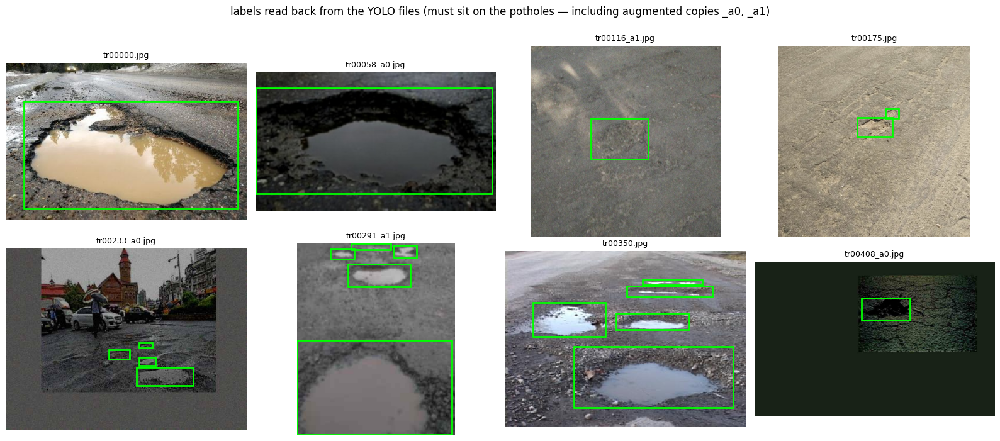

In [ ]:
YOLO_DIR = "/content/yolo_data" if IN_COLAB else os.path.abspath("./yolo_data")
shutil.rmtree(YOLO_DIR, ignore_errors=True)          # always rebuild → no stale label caches
for sp in ("train", "val", "test"):
    os.makedirs(f"{YOLO_DIR}/images/{sp}"); os.makedirs(f"{YOLO_DIR}/labels/{sp}")

def yolo_label_lines(boxes, w, h):
    lines = []
    for x1, y1, x2, y2 in boxes:
        x1, x2 = max(0.0, x1), min(float(w), x2); y1, y2 = max(0.0, y1), min(float(h), y2)
        if x2 - x1 < 1 or y2 - y1 < 1: continue
        lines.append(f"0 {(x1 + x2) / 2 / w:.6f} {(y1 + y2) / 2 / h:.6f} {(x2 - x1) / w:.6f} {(y2 - y1) / h:.6f}")
    return lines

def write_split(recs, split, n_aug=0, seed=0):
    rng = np.random.default_rng(seed)
    n_files = 0
    for k, rec in enumerate(recs):
        img, boxes = load_sample(rec)                                   # RGB uint8
        variants = [(img, boxes, "")] + [(*augment(img, boxes, rng), f"_a{a}") for a in range(n_aug)]
        for im, bx, suf in variants:
            name = f"{split[:2]}{k:05d}{suf}"
            cv2.imwrite(f"{YOLO_DIR}/images/{split}/{name}.jpg", cv2.cvtColor(im, cv2.COLOR_RGB2BGR), [int(cv2.IMWRITE_JPEG_QUALITY), 95])
            h, w = im.shape[:2]
            lines = yolo_label_lines(bx, w, h)
            with open(f"{YOLO_DIR}/labels/{split}/{name}.txt", "w") as f: f.write("\n".join(lines) + ("\n" if lines else ""))
            n_files += 1
    return n_files

t0 = time.time()
n_tr = write_split(train_recs, "train", n_aug=CFG["N_OFFLINE_AUG"], seed=CFG["SEED"])
n_va = write_split(val_recs, "val"); n_te = write_split(test_recs, "test")
YAML_PATH = f"{YOLO_DIR}/data.yaml"
with open(YAML_PATH, "w") as f:
    f.write(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: pothole\n")
print(f"YOLO dataset written in {time.time()-t0:.0f}s → train {n_tr} files ({len(train_recs)} originals × {1+CFG['N_OFFLINE_AUG']}) | val {n_va} | test {n_te}")

# ---- visual check: read the label files back and draw them ----
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
files = sorted(os.listdir(f"{YOLO_DIR}/images/train"))
step = max(1, len(files) // 8)
for ax, fn in zip(axes.ravel(), files[::step]):
    im = cv2.cvtColor(cv2.imread(f"{YOLO_DIR}/images/train/{fn}"), cv2.COLOR_BGR2RGB); h, w = im.shape[:2]
    ax.imshow(im); ax.axis("off"); ax.set_title(fn, fontsize=9)
    for ln in open(f"{YOLO_DIR}/labels/train/{os.path.splitext(fn)[0]}.txt").read().split("\n"):
        if not ln.strip(): continue
        _, xc, yc, bw, bh = map(float, ln.split())
        draw_boxes(ax, [[(xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h]], "lime")
plt.suptitle("labels read back from the YOLO files (must sit on the potholes — including augmented copies _a0, _a1)", y=0.995)
plt.tight_layout(); plt.show()

## 7 · Train YOLO
Starts from COCO-pretrained weights; cosine LR; automatic mixed precision; early stopping; best/last checkpoints saved to your output folder. **If Colab disconnects**, reconnect and *Run all* again — an unfinished run is resumed automatically.

In [ ]:
RUN_NAME = PREFIX + "yolo_run"
RUN_DIR  = os.path.join(OUT_DIR, RUN_NAME)
last_pt  = os.path.join(RUN_DIR, "weights", "last.pt")
best_pt  = os.path.join(RUN_DIR, "weights", "best.pt")

train_kwargs = dict(
    data=YAML_PATH, epochs=EPOCHS, patience=CFG["PATIENCE"], imgsz=IMGSZ, batch=CFG["BATCH"],
    device=DEVICE, workers=CFG["NUM_WORKERS"], project=OUT_DIR, name=RUN_NAME, exist_ok=True,
    seed=CFG["SEED"], cos_lr=True, amp=True, plots=True, close_mosaic=10,
    # online augmentation (applied on top of the offline copies)
    mosaic=1.0, mixup=0.1, hsv_h=0.02, hsv_s=0.7, hsv_v=0.45, scale=0.6, translate=0.1, degrees=0.0, fliplr=0.5,
)

def new_yolo():
    try:
        return YOLO(CFG["MODEL"])
    except Exception as e:
        print("⚠️ could not load", CFG["MODEL"], "→", repr(e)[:120], "\n   falling back to yolov8n.pt")
        return YOLO("yolov8n.pt")

finished = resumable = False
if CFG["RESUME"] and os.path.exists(last_pt):
    try:
        _ck = torch.load(last_pt, map_location="cpu", weights_only=False)
        finished = _ck.get("optimizer") is None          # Ultralytics strips the optimizer when a run completes
        resumable = not finished; del _ck
    except Exception as e:
        print("Could not inspect last.pt (", repr(e)[:100], ") → starting fresh")

det = None
try:
    if finished and os.path.exists(best_pt):
        print("✔ A finished run already exists in", RUN_DIR, "→ skipping training.")
    elif resumable:
        print("↻ Resuming unfinished run from", last_pt)
        det = YOLO(last_pt); det.train(resume=True)
    else:
        det = new_yolo(); det.train(**train_kwargs)
except KeyboardInterrupt:
    print("Interrupted – the best checkpoint so far is kept.")

if det is not None and getattr(det, "trainer", None) is not None and getattr(det.trainer, "save_dir", None):
    RUN_DIR = str(det.trainer.save_dir)                  # actual folder Ultralytics used
best_pt = os.path.join(RUN_DIR, "weights", "best.pt")
assert os.path.exists(best_pt), f"best.pt not found in {RUN_DIR}/weights – training did not produce a checkpoint."
print("best weights:", best_pt)

Ultralytics 8.4.209 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.7, hsv_v=0.45, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_run, nbs=64, nms=None, opset=None, optimize=False, opti

### Learning curves

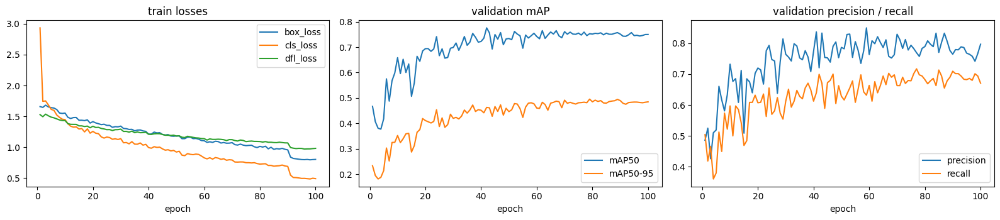

In [ ]:
try:
    import pandas as pd
    df = pd.read_csv(os.path.join(RUN_DIR, "results.csv")); df.columns = df.columns.str.strip()
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
    for c in ("train/box_loss", "train/cls_loss", "train/dfl_loss"):
        if c in df: ax[0].plot(df["epoch"], df[c], label=c.split("/")[1])
    ax[0].set_title("train losses"); ax[0].legend(); ax[0].set_xlabel("epoch")
    for c, lab in (("metrics/mAP50(B)", "mAP50"), ("metrics/mAP50-95(B)", "mAP50-95")):
        if c in df: ax[1].plot(df["epoch"], df[c], label=lab)
    ax[1].set_title("validation mAP"); ax[1].legend(); ax[1].set_xlabel("epoch")
    for c, lab in (("metrics/precision(B)", "precision"), ("metrics/recall(B)", "recall")):
        if c in df: ax[2].plot(df["epoch"], df[c], label=lab)
    ax[2].set_title("validation precision / recall"); ax[2].legend(); ax[2].set_xlabel("epoch")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("Could not plot curves:", repr(e)[:120])

## 8 · Evaluation helpers (own NumPy implementation — AP, precision/recall/F1, threshold calibration)

In [ ]:
def box_iou_np(a, b):
    """a: (N,4), b: (M,4) → (N,M) IoU."""
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)), dtype=np.float32)
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / np.maximum(aa[:, None] + ab[None, :] - inter, 1e-9)

def ap_at_iou(preds, gts, thr):
    """preds: list of (boxes, scores) per image; gts: list of (M,4) arrays. All-point-interpolated AP."""
    n_gt = sum(len(g) for g in gts)
    if n_gt == 0: return float("nan")
    dets = [(float(s), i, j) for i, (b, sc) in enumerate(preds) for j, s in enumerate(sc)]
    if not dets: return 0.0
    dets.sort(key=lambda d: -d[0])
    matched = [np.zeros(len(g), dtype=bool) for g in gts]
    tp = np.zeros(len(dets)); fp = np.zeros(len(dets))
    for k, (s, i, j) in enumerate(dets):
        g = gts[i]
        if len(g) == 0: fp[k] = 1; continue
        ious = box_iou_np(preds[i][0][j:j + 1], g)[0]
        ious = np.where(matched[i], -1.0, ious)
        m = int(ious.argmax())
        if ious[m] >= thr: tp[k] = 1; matched[i][m] = True
        else: fp[k] = 1
    ctp, cfp = np.cumsum(tp), np.cumsum(fp)
    rec = ctp / n_gt; prec = ctp / np.maximum(ctp + cfp, 1e-9)
    mrec = np.concatenate([[0.0], rec, [1.0]]); mpre = np.concatenate([[0.0], prec, [0.0]])
    for i in range(len(mpre) - 2, -1, -1): mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))

def evaluate_preds(preds, gts):
    thrs = np.arange(0.5, 0.96, 0.05)
    aps = [ap_at_iou(preds, gts, t) for t in thrs]
    return dict(ap50=aps[0], ap75=aps[5], ap=float(np.nanmean(aps)))

def prf_at_threshold(preds, gts, score_thr, iou_thr=0.5):
    tp = fp = fn = 0
    for (b, s), g in zip(preds, gts):
        keep = s >= score_thr; b, s = b[keep], s[keep]
        order = np.argsort(-s); b = b[order]
        used = np.zeros(len(g), dtype=bool)
        for k in range(len(b)):
            if len(g) == 0: fp += 1; continue
            ious = np.where(used, -1.0, box_iou_np(b[k:k + 1], g)[0]); m = int(ious.argmax())
            if ious[m] >= iou_thr: tp += 1; used[m] = True
            else: fp += 1
        fn += int((~used).sum())
    p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
    return dict(precision=p, recall=r, f1=(2 * p * r / (p + r)) if (p + r) > 0 else 0.0, tp=tp, fp=fp, fn=fn)

def best_f1_threshold(preds, gts):
    """Threshold maximising F1. If F1 is (near-)flat over a range, take the middle of that range → more robust than its edge."""
    ts = np.arange(0.05, 0.96, 0.01)
    f1s = np.array([prf_at_threshold(preds, gts, t)["f1"] for t in ts])
    plateau = ts[f1s >= f1s.max() - 0.005]
    return float(np.median(plateau)), float(f1s.max())

## 9 · Final evaluation on the untouched test set + threshold calibration
The confidence threshold is picked on the **validation** set (max F1 @ IoU 0.5) and then applied to the **test** set — so the test numbers are honest.

calibrated threshold (from validation, max F1) : 0.27  (val F1 0.772)

TEST (own implementation)  AP50 0.808 | AP75 0.605 | AP50:95 0.527
TEST @thr 0.27: precision 0.792 | recall 0.732 | F1 0.761  (TP 175, FP 46, FN 64)
TEST @thr 0.50: precision 0.938 | recall 0.636 | F1 0.758
Ultralytics 8.4.209 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2107.2±449.5 MB/s, size: 78.7 KB)
val: Scanning /content/yolo_data/labels/test... 99 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 99/99 1.9Kit/s 0.1s
val: New cache created: /content/yolo_data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 6.0it/s 1.2s
                   all         99        239      0.877      0.678      0.807      0.528
Speed: 0.8ms preprocess, 5.0ms inference, 0.0ms loss, 1.4ms postprocess p

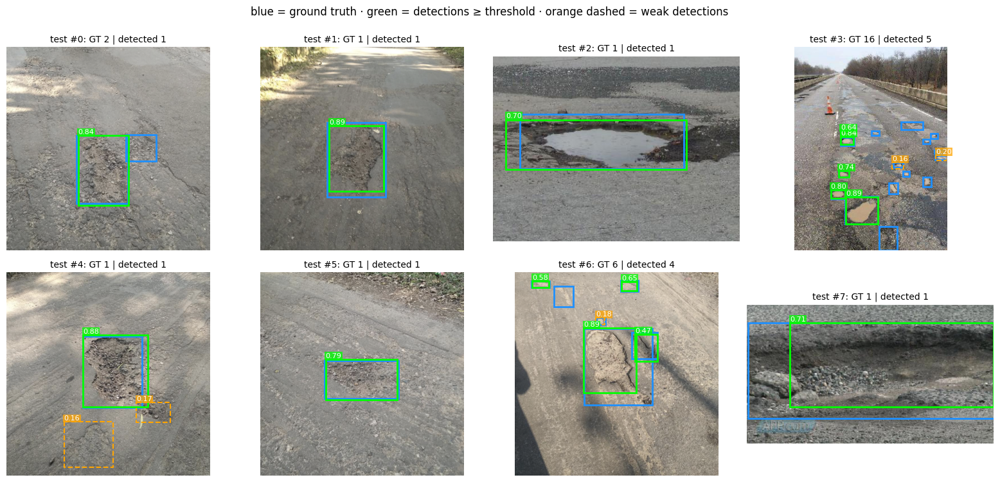

In [ ]:
det = YOLO(best_pt)

def yolo_predict(detector, recs, conf=0.001, batch=16):
    """Run YOLO on records (same pixels/coordinates as the labels). Returns preds [(boxes, scores)], gts [boxes]."""
    preds, gts = [], []
    for i in range(0, len(recs), batch):
        chunk = [load_sample(r) for r in recs[i:i + batch]]
        frames = [cv2.cvtColor(im, cv2.COLOR_RGB2BGR) for im, _ in chunk]          # Ultralytics expects BGR arrays
        results = detector.predict(frames, imgsz=IMGSZ, conf=conf, iou=0.6, max_det=100, verbose=False, device=DEVICE)
        for r, (_, bx) in zip(results, chunk):
            preds.append((r.boxes.xyxy.cpu().numpy().astype(np.float32), r.boxes.conf.cpu().numpy().astype(np.float32)))
            gts.append(bx)
    return preds, gts

val_preds, val_gts = yolo_predict(det, val_recs)
BEST_THR, val_f1 = best_f1_threshold(val_preds, val_gts)
test_preds, test_gts = yolo_predict(det, test_recs)
test_ap = evaluate_preds(test_preds, test_gts)
at_best = prf_at_threshold(test_preds, test_gts, BEST_THR)
at_half = prf_at_threshold(test_preds, test_gts, 0.5)

print(f"calibrated threshold (from validation, max F1) : {BEST_THR:.2f}  (val F1 {val_f1:.3f})\n")
print(f"TEST (own implementation)  AP50 {test_ap['ap50']:.3f} | AP75 {test_ap['ap75']:.3f} | AP50:95 {test_ap['ap']:.3f}")
print(f"TEST @thr {BEST_THR:.2f}: precision {at_best['precision']:.3f} | recall {at_best['recall']:.3f} | F1 {at_best['f1']:.3f}  (TP {at_best['tp']}, FP {at_best['fp']}, FN {at_best['fn']})")
print(f"TEST @thr 0.50: precision {at_half['precision']:.3f} | recall {at_half['recall']:.3f} | F1 {at_half['f1']:.3f}")
try:                                                                   # Ultralytics' own numbers for cross-checking
    v = det.val(data=YAML_PATH, split="test", imgsz=IMGSZ, batch=16, conf=0.001, iou=0.6, device=DEVICE, plots=False, verbose=False)
    print(f"TEST (Ultralytics official)  mAP50 {v.box.map50:.3f} | mAP50-95 {v.box.map:.3f} | P {v.box.mp:.3f} | R {v.box.mr:.3f}")
except Exception as e:
    print("Ultralytics val skipped:", repr(e)[:100])

# ---- save final model + metadata ----
FINAL_PT = os.path.join(OUT_DIR, PREFIX + "pothole_yolo_best.pt"); shutil.copy(best_pt, FINAL_PT)
CONFIG_JSON = os.path.join(OUT_DIR, PREFIX + "config.json")
with open(CONFIG_JSON, "w") as f:
    json.dump(dict(model=CFG["MODEL"], imgsz=IMGSZ, class_names=["pothole"], score_threshold=BEST_THR,
                   test_metrics=dict(ap50=test_ap["ap50"], ap=test_ap["ap"], precision=at_best["precision"], recall=at_best["recall"], f1=at_best["f1"]),
                   usage="from ultralytics import YOLO; YOLO('pothole_yolo_best.pt').predict(frame_bgr, conf=score_threshold, imgsz=imgsz)"), f, indent=2)
print("\nSaved:", FINAL_PT, "and", CONFIG_JSON)

# ---- test images: blue = ground truth, lime = detection ≥ threshold, orange dashed = weak (0.15 … threshold)
n_show = min(8, len(test_recs))
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for k, ax in enumerate(axes.ravel()):
    ax.axis("off")
    if k >= n_show: continue
    im, _ = load_sample(test_recs[k]); b, s = test_preds[k]
    ax.imshow(im); draw_boxes(ax, test_gts[k], "dodgerblue", lw=2)
    weak = (s >= 0.15) & (s < BEST_THR); strong = s >= BEST_THR
    draw_boxes(ax, b[weak], "orange", s[weak], lw=1.5, ls="--"); draw_boxes(ax, b[strong], "lime", s[strong], lw=2)
    ax.set_title(f"test #{k}: GT {len(test_gts[k])} | detected {int(strong.sum())}", fontsize=10)
plt.suptitle("blue = ground truth · green = detections ≥ threshold · orange dashed = weak detections", y=0.995)
plt.tight_layout(); plt.show()

## 10 · Export (optional)
`pothole_yolo_best.pt` is the main deliverable. ONNX / OpenVINO exports are for faster CPU inference or other runtimes; each is wrapped in try/except so a failure never affects the rest. The ONNX file is re-loaded and compared with the `.pt` model on a test image.

In [ ]:
exported = {}
for fmt in CFG["EXPORT"]:
    try:
        p = YOLO(best_pt).export(format=fmt, imgsz=IMGSZ)
        exported[fmt] = str(p); print(f"✔ exported {fmt}: {p}")
    except Exception as e:
        print(f"✘ {fmt} export failed (not critical): {repr(e)[:160]}")

if "onnx" in exported and test_recs:
    try:
        im, _ = load_sample(test_recs[0]); frame = cv2.cvtColor(im, cv2.COLOR_RGB2BGR)
        a = YOLO(best_pt).predict(frame, imgsz=IMGSZ, conf=BEST_THR, verbose=False, device="cpu")[0]
        b = YOLO(exported["onnx"], task="detect").predict(frame, imgsz=IMGSZ, conf=BEST_THR, verbose=False, device="cpu")[0]
        print(f"verification on a test image: .pt → {len(a.boxes)} detections | ONNX → {len(b.boxes)} detections (≥ {BEST_THR:.2f})")
    except Exception as e:
        print("ONNX verification skipped:", repr(e)[:120])

Ultralytics 8.4.209 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/pothole_detector/yolo_run/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (5.3 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 313ms
Prepared 4 packages in 1.02s
Installed 4 packages in 57ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.1
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 2.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18

## 11 · Real-time video script
This cell writes `realtime_pothole.py`, a standalone script for **webcam / video file / RTSP stream**. It reads live streams in a background thread (always processes the newest frame), can skip frames for speed, draws FPS + boxes, optionally saves the annotated video, and has an optional anti-flicker filter. You run it on your laptop (see the last cell of this notebook for the exact commands).

In [ ]:
%%writefile realtime_pothole.py
#!/usr/bin/env python3
# Real-time pothole detection with a fine-tuned YOLO model.
#
#   pip install ultralytics opencv-python
#   python realtime_pothole.py --weights pothole_yolo_best.pt --source 0                 # webcam
#   python realtime_pothole.py --weights pothole_yolo_best.pt --source road.mp4          # video file
#   python realtime_pothole.py --weights pothole_yolo_best.pt --source rtsp://...        # IP camera / phone stream
#   python realtime_pothole.py --weights best.pt --source road.mp4 --save out.mp4 --no-show
#
# Speed knobs (CPU): --imgsz 416 (or 320), --skip 1 or 2 (detect every 2nd/3rd frame), --device cpu
# Press  q  in the video window to quit.
import argparse, json, os, sys, threading, time
import cv2
import numpy as np


def box_iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


class SimpleTracker:
    """Very small IoU tracker used only to suppress one-frame false positives.
    A box is shown once it has been detected in `min_hits` detection runs, and kept for `max_miss` runs after it disappears.
    min_hits=1 disables the filtering (every detection is shown immediately)."""

    def __init__(self, min_hits=1, max_miss=2, iou_thr=0.3):
        self.min_hits, self.max_miss, self.iou_thr = min_hits, max_miss, iou_thr
        self.tracks = []

    def update(self, boxes, scores):
        for t in self.tracks:
            t["matched"] = False
        for j in np.argsort(-np.asarray(scores)) if len(scores) else []:
            best, best_iou = -1, self.iou_thr
            for ti, t in enumerate(self.tracks):
                if t["matched"]:
                    continue
                v = box_iou(t["box"], boxes[j])
                if v >= best_iou:
                    best, best_iou = ti, v
            if best >= 0:
                t = self.tracks[best]
                t["box"] = 0.5 * t["box"] + 0.5 * np.asarray(boxes[j], dtype=np.float32)   # light smoothing
                t["score"] = float(scores[j]); t["hits"] += 1; t["miss"] = 0; t["matched"] = True
            else:
                self.tracks.append(dict(box=np.asarray(boxes[j], dtype=np.float32).copy(), score=float(scores[j]),
                                        hits=1, miss=0, matched=True))
        for t in self.tracks:
            if not t["matched"]:
                t["miss"] += 1
        self.tracks = [t for t in self.tracks if t["miss"] <= self.max_miss]

    def visible(self):
        return [(t["box"], t["score"]) for t in self.tracks if t["hits"] >= self.min_hits]


class FrameSource:
    """Live sources (webcam / network stream) are read in a background thread so we always process the NEWEST frame
    instead of falling behind. Files are read sequentially so no frame is dropped."""

    def __init__(self, src):
        self.live = isinstance(src, int) or str(src).lower().startswith(("rtsp://", "http://", "https://", "rtmp://"))
        self.cap = cv2.VideoCapture(src)
        if not self.cap.isOpened():
            raise RuntimeError(f"Could not open video source: {src}")
        self.fps = self.cap.get(cv2.CAP_PROP_FPS) or 25.0
        self._frame, self._idx, self._ok, self._lock = None, 0, True, threading.Lock()
        if self.live:
            try: self.cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)
            except Exception: pass
            threading.Thread(target=self._loop, daemon=True).start()

    def _loop(self):
        while self._ok:
            ok, f = self.cap.read()
            if not ok:
                self._ok = False; break
            with self._lock:
                self._frame, self._idx = f, self._idx + 1

    def read(self, last_idx=-1):
        """returns (frame or None, idx, alive)"""
        if self.live:
            with self._lock:
                f, i = self._frame, self._idx
            if f is None or i == last_idx:
                return None, last_idx, self._ok          # nothing new yet
            return f, i, True
        ok, f = self.cap.read()
        return (f, last_idx + 1, True) if ok else (None, last_idx, False)

    def release(self):
        self._ok = False; self.cap.release()


def load_detector(weights):
    from ultralytics import YOLO
    return YOLO(weights, task="detect")


def detect(det, frame, conf, imgsz, device, iou=0.5):
    kw = dict(imgsz=imgsz, conf=conf, iou=iou, verbose=False, max_det=50)
    if device: kw["device"] = device
    r = det.predict(frame, **kw)[0]
    return r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()


def draw(frame, items, fps=None, n_det=None):
    for box, score in items:
        x1, y1, x2, y2 = [int(v) for v in box]
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
        label = f"pothole {score:.2f}"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(frame, (x1, max(0, y1 - th - 6)), (x1 + tw + 4, y1), (0, 160, 0), -1)
        cv2.putText(frame, label, (x1 + 2, max(10, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
    if fps is not None:
        cv2.putText(frame, f"{fps:4.1f} FPS | {len(items)} pothole(s)", (10, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 0), 4, cv2.LINE_AA)
        cv2.putText(frame, f"{fps:4.1f} FPS | {len(items)} pothole(s)", (10, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
    return frame


def default_conf(weights):
    for d in (os.path.dirname(os.path.abspath(weights)), os.path.dirname(os.path.dirname(os.path.abspath(weights)))):
        p = os.path.join(d, "config.json")
        if os.path.exists(p):
            try: return float(json.load(open(p))["score_threshold"])
            except Exception: pass
    return 0.35


def main(argv=None):
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--weights", required=True)
    ap.add_argument("--source", default="0", help="0 = webcam, or a video file / rtsp:// / http:// stream")
    ap.add_argument("--conf", type=float, default=None, help="score threshold (default: from config.json next to the weights, else 0.35)")
    ap.add_argument("--imgsz", type=int, default=640)
    ap.add_argument("--skip", type=int, default=0, help="skip N frames between detections (reuse last result) – more speed")
    ap.add_argument("--min-hits", type=int, default=1, help="show a box only after it was seen in N detection runs (2-3 removes flicker; 1 = off)")
    ap.add_argument("--device", default=None, help="'cpu', '0' (GPU) … default: automatic")
    ap.add_argument("--save", default=None, help="write annotated video to this path (e.g. out.mp4)")
    ap.add_argument("--no-show", action="store_true", help="do not open a window (headless / Colab)")
    ap.add_argument("--max-frames", type=int, default=0)
    a = ap.parse_args(argv)

    conf = a.conf if a.conf is not None else default_conf(a.weights)
    src = int(a.source) if str(a.source).isdigit() else a.source
    device = (int(a.device) if str(a.device).isdigit() else a.device) if a.device is not None else None
    det = load_detector(a.weights)
    srcr = FrameSource(src)
    tracker = SimpleTracker(min_hits=a.min_hits)
    writer, fps_s, t_prev, n, last_idx, n_run = None, None, time.time(), 0, -1, 0
    t_start = time.time()
    print(f"conf={conf:.2f} imgsz={a.imgsz} skip={a.skip} min_hits={a.min_hits} live={srcr.live}  (press q to quit)")

    while True:
        frame, last_idx, alive = srcr.read(last_idx)
        if frame is None:
            if not alive: break
            time.sleep(0.002); continue
        if n % (a.skip + 1) == 0:
            boxes, scores = detect(det, frame, conf, a.imgsz, device)
            tracker.update(boxes, scores); n_run += 1
        now = time.time(); inst = 1.0 / max(now - t_prev, 1e-6); t_prev = now
        fps_s = inst if fps_s is None else 0.9 * fps_s + 0.1 * inst
        out = draw(frame.copy(), tracker.visible(), fps=fps_s)
        if a.save:
            if writer is None:
                h, w = out.shape[:2]
                writer = cv2.VideoWriter(a.save, cv2.VideoWriter_fourcc(*"mp4v"), srcr.fps, (w, h))
            writer.write(out)
        if not a.no_show:
            cv2.imshow("Pothole detector (q = quit)", out)
            if cv2.waitKey(1) & 0xFF == ord("q"): break
        n += 1
        if a.max_frames and n >= a.max_frames: break

    srcr.release()
    if writer is not None: writer.release()
    if not a.no_show: cv2.destroyAllWindows()
    el = max(time.time() - t_start, 1e-6)
    print(f"processed {n} frames in {el:.1f}s → {n / el:.1f} FPS average ({n_run} detector runs)" + (f" | saved: {a.save}" if a.save else ""))


if __name__ == "__main__":
    main()

Overwriting realtime_pothole.py


In [ ]:
SCRIPT_OUT = os.path.join(OUT_DIR, "realtime_pothole.py")
shutil.copy("realtime_pothole.py", SCRIPT_OUT)
print("Script saved to:", SCRIPT_OUT)

Script saved to: /content/drive/MyDrive/pothole_detector/realtime_pothole.py


## 12 · Download your files

In [ ]:
to_get = [FINAL_PT, CONFIG_JSON, SCRIPT_OUT] + [p for p in exported.values() if os.path.isfile(p)]
print("Everything is also stored in:", OUT_DIR)
for p in to_get: print("  •", p)
if IN_COLAB:
    try:
        from google.colab import files
        for p in to_get: files.download(p)
    except Exception as e:
        print("Download skipped:", repr(e)[:100])

Everything is also stored in: /content/drive/MyDrive/pothole_detector
  • /content/drive/MyDrive/pothole_detector/pothole_yolo_best.pt
  • /content/drive/MyDrive/pothole_detector/config.json
  • /content/drive/MyDrive/pothole_detector/realtime_pothole.py
  • /content/drive/MyDrive/pothole_detector/yolo_run/weights/best.onnx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Run it on your laptop (copy-paste)
```bash
pip install ultralytics opencv-python
python realtime_pothole.py --weights pothole_yolo_best.pt --source 0                          # webcam
python realtime_pothole.py --weights pothole_yolo_best.pt --source road.mp4                   # video file
python realtime_pothole.py --weights pothole_yolo_best.pt --source rtsp://user:pass@ip/stream # IP camera
# slower laptop?  add:  --imgsz 416 --skip 1        flicker?  add:  --min-hits 2
```
Keep `config.json` next to the weights and the script uses your calibrated threshold automatically (override with `--conf 0.5`).

**Use in your own Python code:**
```python
from ultralytics import YOLO
det = YOLO("pothole_yolo_best.pt")
r = det.predict(frame_bgr, conf=0.35, imgsz=640, verbose=False)[0]      # frame_bgr = OpenCV image
for (x1, y1, x2, y2), s in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist()): ...
```

## 13 · Try it on YOUR images (Google photos, phone pictures, dash-cam frames)
Re-run this cell as often as you like — it asks you to **upload files** (or put image URLs in `IMAGE_URLS`). Green = detection ≥ calibrated threshold, orange dashed = weak candidates. `TTA=True` uses YOLO's built-in test-time augmentation (slower, a bit more accurate).

Select image files to test (or cancel to skip)…


Saving images (1).jpg to images (1) (1).jpg
Saving images.jpg to images (2).jpg
Saving Dirtroadpotholes.JPG to Dirtroadpotholes (1).JPG
images (1) (1).jpg: 390x280 → 4 detections ≥ 0.27 (+0 weak)
images (2).jpg: 596x335 → 2 detections ≥ 0.27 (+0 weak)
Dirtroadpotholes (1).JPG: 250x333 → 1 detections ≥ 0.27 (+1 weak)


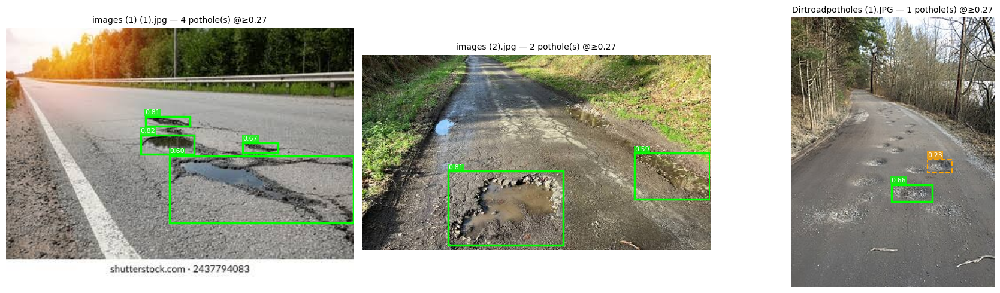

In [ ]:
from PIL import Image, ImageOps
IMAGE_URLS = [          # optional – direct image links (many sites block hot-linking; uploading always works)
    # "https://example.com/pothole.jpg",
]
THRESHOLD = None        # None = use the calibrated threshold from section 9
TTA = False
LOW = 0.15              # also show weaker candidates down to this score (orange)

def read_rgb_any(path):
    return np.array(ImageOps.exif_transpose(Image.open(path)).convert("RGB"))     # webp/png/jpg, EXIF rotation, alpha, grayscale

def detect_image(detector, img_rgb, low=0.15, tta=False):
    r = detector.predict(cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR), imgsz=IMGSZ, conf=low, iou=0.5, augment=tta,
                         max_det=100, verbose=False, device=DEVICE)[0]
    return r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()

def run_on_paths(paths):
    thr = THRESHOLD if THRESHOLD is not None else BEST_THR
    n = len(paths)
    if n == 0: print("No images to process."); return
    cols = min(3, n); rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 5 * rows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, p in zip(axes.ravel(), paths):
        try:
            img = read_rgb_any(p)
            b, s = detect_image(det, img, low=LOW, tta=TTA); strong = s >= thr
            ax.imshow(img); draw_boxes(ax, b[~strong], "orange", s[~strong], lw=1.5, ls="--"); draw_boxes(ax, b[strong], "lime", s[strong], lw=2.5)
            ax.set_title(f"{os.path.basename(p)[:28]} — {int(strong.sum())} pothole(s) @≥{thr:.2f}", fontsize=10)
            print(f"{os.path.basename(p)}: {img.shape[1]}x{img.shape[0]} → {int(strong.sum())} detections ≥ {thr:.2f} (+{int((~strong).sum())} weak)")
        except Exception as e:
            ax.set_title("could not read image", color="red"); print(f"{p}: FAILED – {repr(e)[:120]}")
    plt.tight_layout(); plt.show()

MY_DIR = "/content/my_images" if IN_COLAB else os.path.abspath("./my_images"); os.makedirs(MY_DIR, exist_ok=True)
paths = []
for i, u in enumerate(IMAGE_URLS):
    try:
        req = urllib.request.Request(u, headers={"User-Agent": "Mozilla/5.0"}); dst = os.path.join(MY_DIR, f"url_{i}.jpg")
        with urllib.request.urlopen(req, timeout=20) as r, open(dst, "wb") as f: f.write(r.read())
        paths.append(dst)
    except Exception as e:
        print("download failed:", u[:70], repr(e)[:80])
if IN_COLAB:
    try:
        from google.colab import files
        print("Select image files to test (or cancel to skip)…")
        for name, data in files.upload().items():
            dst = os.path.join(MY_DIR, name); open(dst, "wb").write(data); paths.append(dst)
    except Exception as e:
        print("upload skipped:", repr(e)[:80])
run_on_paths(paths)

### Tuning on your own images
* **Too many false boxes?** raise `THRESHOLD` (e.g. 0.6) and re-run — no retraining needed.
* **Missing potholes?** lower it (e.g. 0.3) and/or set `TTA = True`.
* **Still weak on a type of scene** (night, wet road, snow, dirt road, aerial view)? That scene isn't in the training data — add a few dozen labelled images of it and retrain; this is the single most effective improvement.

## 14 · Try it on a VIDEO
Upload a short clip (dash-cam, phone video). The real-time script processes it and shows the annotated result plus the **average FPS on this machine**. Colab has no webcam access, so webcam/RTSP tests are done on your laptop.

In [ ]:
from IPython.display import Video, display
VIDEO_PATH = None                      # or set a path to a video already in Colab, e.g. "/content/clip.mp4"
SKIP, MIN_HITS, VIDEO_IMGSZ = 0, 1, IMGSZ

if VIDEO_PATH is None and IN_COLAB:
    try:
        from google.colab import files
        print("Select a video file (mp4/avi/mov) – or cancel to skip…")
        up = files.upload()
        if up:
            VIDEO_PATH = os.path.join("/content", next(iter(up))); open(VIDEO_PATH, "wb").write(next(iter(up.values())))
    except Exception as e:
        print("upload skipped:", repr(e)[:80])

if VIDEO_PATH and os.path.exists(VIDEO_PATH):
    raw_out, web_out = "/content/pothole_out_raw.mp4", "/content/pothole_out.mp4"
    cmd = [sys.executable, "realtime_pothole.py", "--weights", best_pt, "--source", VIDEO_PATH, "--save", raw_out, "--no-show",
           "--conf", f"{BEST_THR:.3f}", "--imgsz", str(VIDEO_IMGSZ), "--skip", str(SKIP), "--min-hits", str(MIN_HITS)]
    r = subprocess.run(cmd, capture_output=True, text=True); print(r.stdout[-800:], r.stderr[-400:] if r.returncode else "")
    if os.path.exists(raw_out):
        rc = subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", raw_out, "-vcodec", "libx264", "-pix_fmt", "yuv420p", web_out])
        display(Video(web_out if rc.returncode == 0 and os.path.exists(web_out) else raw_out, embed=True, width=720))
        if IN_COLAB:
            try: files.download(web_out if os.path.exists(web_out) else raw_out)
            except Exception: pass
else:
    print("No video selected – skipping.")

Select a video file (mp4/avi/mov) – or cancel to skip…


Saving Pothole video.mp4 to Pothole video (1).mp4
conf=0.27 imgsz=640 skip=0 min_hits=1 live=False  (press q to quit)
processed 821 frames in 17.9s → 45.9 FPS average (821 detector runs) | saved: /content/pothole_out_raw.mp4
 


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>